In [1]:
%matplotlib widget

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import torch
import json
import numpy as np

from helpers.plotting import plot_performance, plot_gradients, plot_weight_matrices, InteractiveSpikePlot, plot_decays

In [2]:
work_dir = Path.cwd()

n_trials = 5

def load_recording(data_name: str, key: str, skip_is: list[int] = []) -> np.ndarray:
    data = []
    for i in range(1, n_trials + 1):
        if i not in skip_is:
            with np.load(work_dir / f"seed_{i}" / "data_net" / f"{data_name}.npz") as d:
                data.append(d[key])
    return np.array(data)

def get_data(data_name: str, skip_is: list[int] = []) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_1" / "data_net" / f"{data_name}.npz") as d:
        keys = list(d.keys())
    return {key: load_recording(data_name, key, skip_is) for key in keys}

def get_data_seed(data_name: str, seed: int) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_{seed}" / "data_net" / f"{data_name}.npz") as d:
        return {key: d[key] for key in list(d.keys())}

def filter_seeds(data: np.ndarray, seeds: list[int]) -> np.ndarray:
    return np.take(data, seeds, axis=0)

def unpack_bits(data: dict[np.ndarray], key: str, suffix: str = "-n_cols") -> np.ndarray:
    unpack_key = key + suffix
    if unpack_key in data.keys():
        return np.unpackbits(data[key], axis=-1, count=int(data[unpack_key])).astype(bool)
    return data[key]

def get_neuron_range(neurons: np.ndarray, neuron_value: int) -> tuple[int, int]:    
    return (
        np.min(np.where(neurons == neuron_value)),
        np.max(np.where(neurons == neuron_value))
    )

def get_neuron_ranges(neurons: np.ndarray, neuron_map: dict[str, int]) -> dict[str, tuple[int, int]]:
    return {k: get_neuron_range(neurons, v) for k, v in neuron_map.items()}   

def load_neurons(seed: int) -> tuple[np.ndarray, dict[str, int], dict[str, tuple[int, int]]]:
    data = np.load(work_dir  / f"seed_{seed}" / "neurons.npz")
    neurons = data["neurons"]
    neuron_map = json.loads(str(data["neuron_map"]))
    neuron_ranges = get_neuron_ranges(neurons, neuron_map)
    return neurons, neuron_map, neuron_ranges

def get_weight_masks(seed: int) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_{seed}" / f"net_weights_masks.npz") as d:
        return {key: d[key] for key in list(d.keys())}

def load_beta(seed: int) -> np.ndarray:
    ckpt = torch.load(f"seed_{seed}/net.checkpoint.pt", map_location="cpu", weights_only=True)

    state = ckpt["model"]

    beta: np.array = state["rec_layers.0.neurons.beta"].numpy()
    return np.clip(beta, 0.0, 1.0)

def beta_to_tau(beta: np.ndarray, dt: float) -> np.ndarray:
    """
    Computes the inverse of 'beta = exp(-dt / tau)'.
    -dt / tau = log(beta)
    tau / -dt = 1/log(beta)
    tau = -dt/log(beta)
    """
    return -dt / np.log(beta)

In [3]:
skip_is = []

[[False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False]
 [False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False]
 [False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False]
 [False False False False False False False False False False False

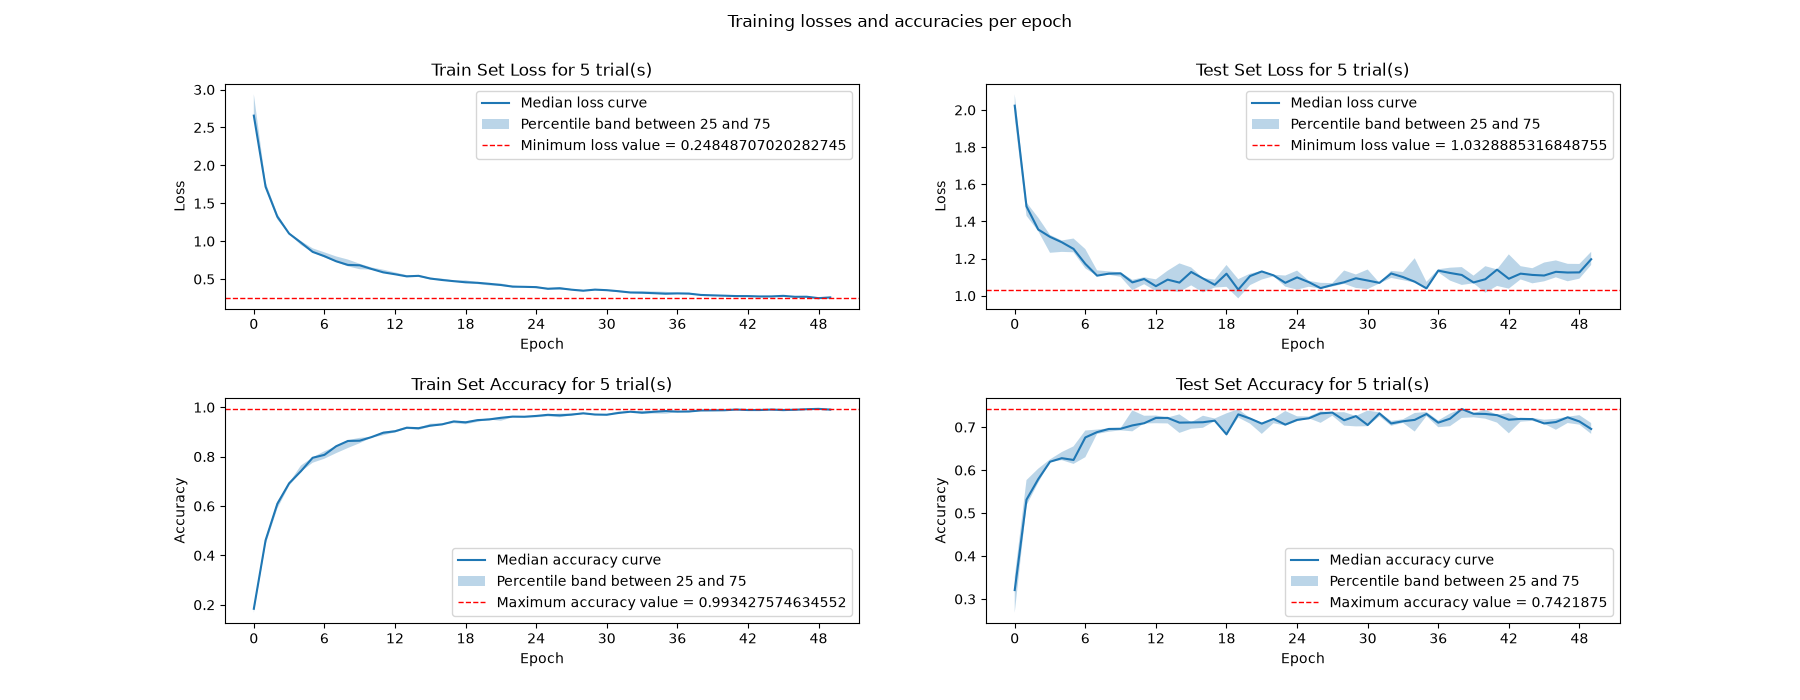

In [4]:
plot_seeds = [0, 1, 2, 3, 4]
perf_data = get_data("performance", skip_is)
print(np.isnan(perf_data["loss_train"]))
plot_performance(
    loss_train=filter_seeds(perf_data["loss_train"], plot_seeds),
    acc_train=filter_seeds(perf_data["acc_train"], plot_seeds),
    loss_test=filter_seeds(perf_data["loss_test"], plot_seeds),
    acc_test=filter_seeds(perf_data["acc_test"], plot_seeds),
)

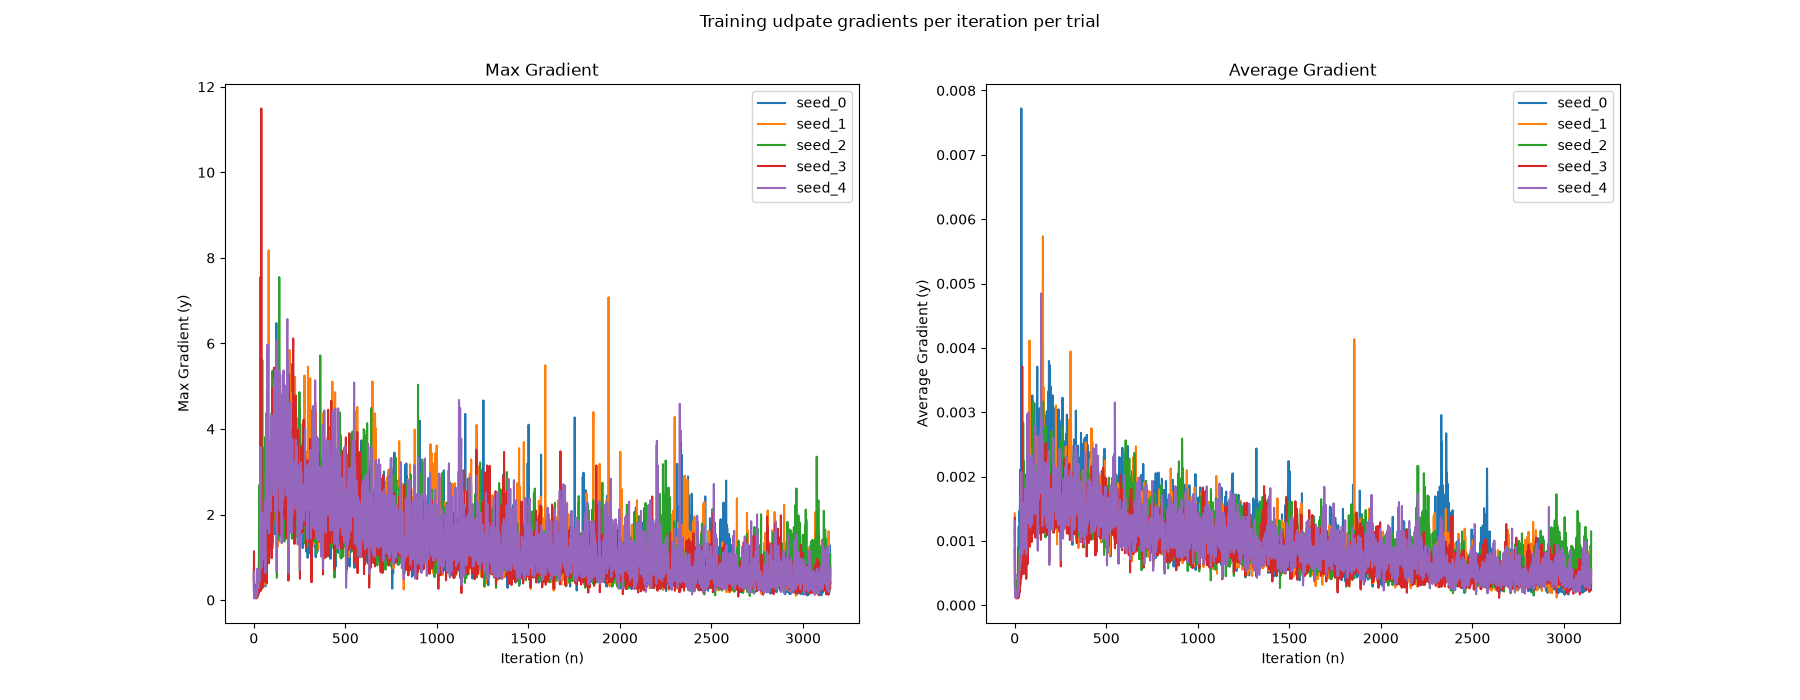

In [5]:
grad_data = get_data("gradients", skip_is)
max_grad_rec = filter_seeds(grad_data["max_grad"], plot_seeds)
avg_grad_rec = filter_seeds(grad_data["avg_grad"], plot_seeds)
plot_gradients(max_grad_rec, avg_grad_rec)

In [ ]:
neurons, neuron_map, neuron_ranges = load_neurons(seed=1)

weights = get_data_seed("weights", seed=1)
print(weights.keys())
weight_masks = get_weight_masks(seed=1)
print(weight_masks.keys())
weights["weights_recurrent_0"] *= weight_masks["recurrent_mask_0"].T        # con_matrix is transposed in linears.py
weights["weights_forward_1"] *= weight_masks["forward_mask_1"].T

keys, datas = zip(*weights.items())
plot_weight_matrices(datas[0], None, add_ranges_to_side=False, name=keys[0])
plot_weight_matrices(datas[1], neuron_ranges, add_ranges_to_side=True, name=keys[1])
plot_weight_matrices(datas[2], neuron_ranges, add_ranges_to_side=False, name=keys[2])

dict_keys(['weights_forward_0', 'weights_recurrent_0', 'weights_forward_1'])
dict_keys(['recurrent_mask_0', 'forward_mask_1'])


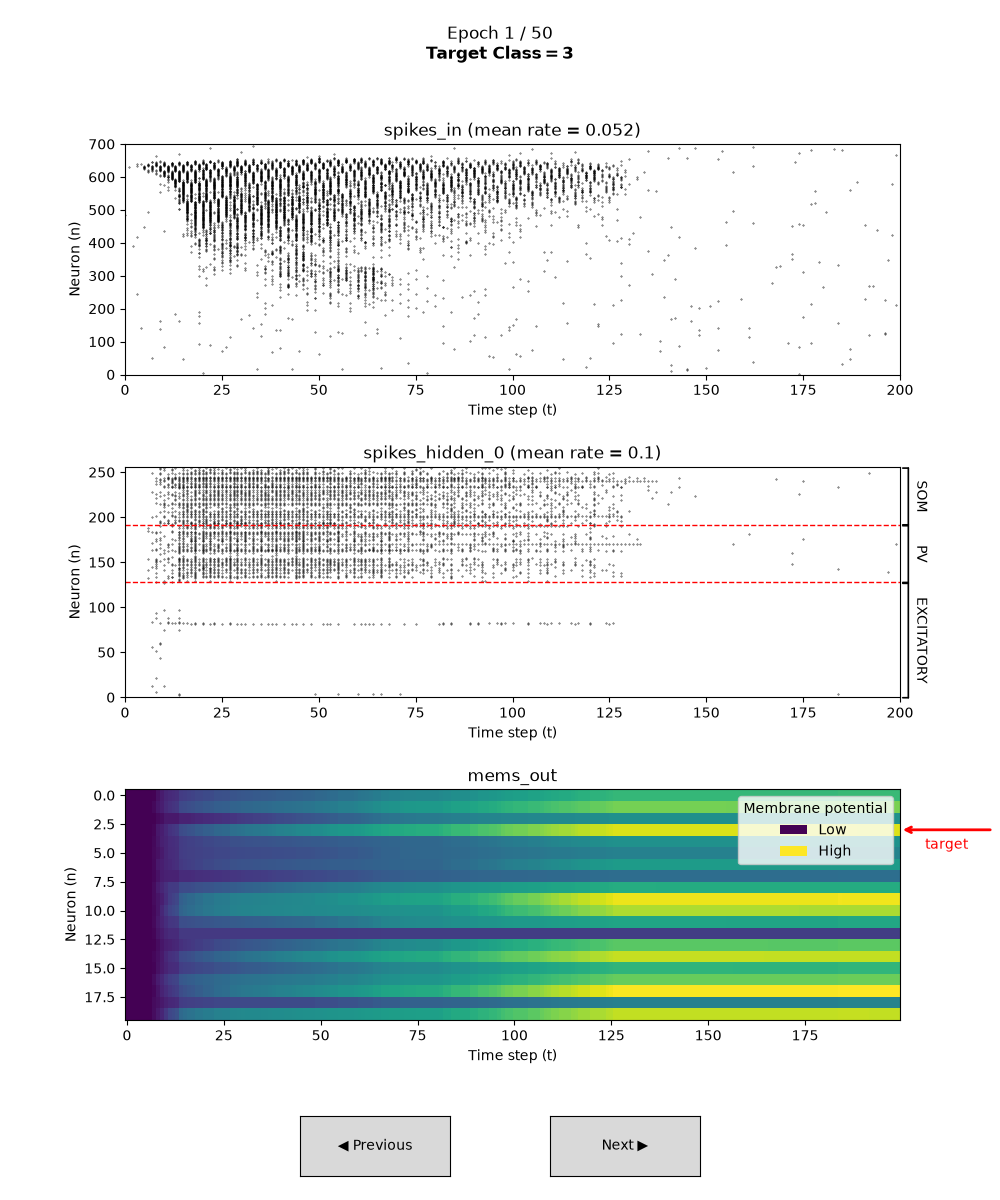

In [29]:
seed=1
neurons, neuron_map, neuron_ranges = load_neurons(seed=seed)

data = get_data_seed("spikes", seed=seed)
layer_spikes = {
    k: unpack_bits(data, k)
    for k in ["spikes_in", "spikes_hidden_0", "mems_out", "targets"]
    if not k.endswith(("-lengths", "-n_cols"))
}

isp = InteractiveSpikePlot(layer_spikes, range(20), neuron_ranges)
# isp.draw()
# isp.save_as_pdf()
isp.save_as_pptx()

{'PV': (np.int64(128), np.int64(191)), 'SOM': (np.int64(192), np.int64(255)), 'EXCITATORY': (np.int64(0), np.int64(127))}


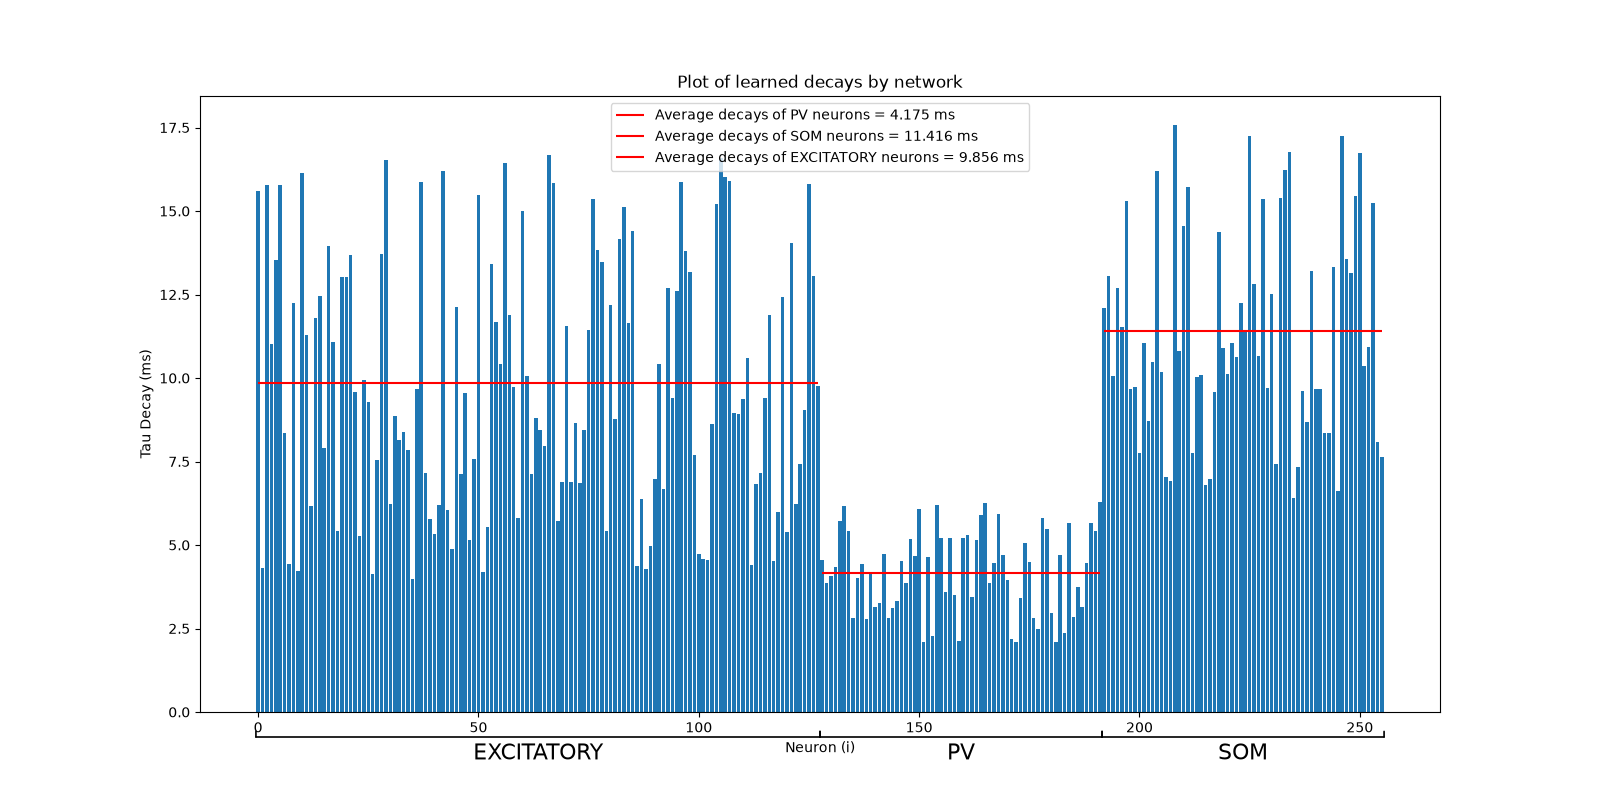

In [4]:
seed = 1
dt = 0.001
beta = load_beta(seed=seed)
neurons, neuron_map, neuron_ranges = load_neurons(seed=seed)
print(neuron_ranges)

plot_decays(beta, dt, neuron_ranges)